# Healthcare Insurance Cost Drivers and Retail Loyalty Analysis

**Question:** Could a retail style rewards program work in health insurance?

**Data:** insurance.xlsx (1,338 records: age, BMI, smoker status, region and charges) and Electronic_sales_Sep2023-Sep2024.xlsx (20,000 electronics purchases).
The two datasets describe different people, so they are analyzed separately.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
insurance = pd.read_excel("insurance.xlsx", sheet_name="insurance")
sales = pd.read_excel("Electronic_sales_Sep2023-Sep2024.xlsx", sheet_name=2)

In [3]:
print("Insurance:", insurance.shape)
print("Sales:", sales.shape)

Insurance: (1338, 7)
Sales: (20000, 16)


In [4]:
#Data quality check
print("Missing values in insurance:")
print(insurance.isna().sum())
print("Duplicate rows in insurance:", insurance.duplicated().sum())

print("\nMissing values in sales:")
print(sales.isna().sum())
print("Duplicate rows in sales:", sales.duplicated().sum())

Missing values in insurance:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows in insurance: 1

Missing values in sales:
Customer ID             0
Age                     0
Gender                  1
Loyalty Member          0
Product Type            0
SKU                     0
Rating                  0
Order Status            0
Payment Method          0
Total Price             0
Unit Price              0
Quantity                0
Purchase Date           0
Shipping Type           0
Add-ons Purchased    4868
Add-on Total            0
dtype: int64
Duplicate rows in sales: 0


In [5]:
#cleaning
insurance = insurance.drop_duplicates()

sales.columns = (sales.columns.str.strip().str.lower()
                 .str.replace(" ", "_").str.replace("-", "_"))
sales["purchase_date"] = pd.to_datetime(sales["purchase_date"])
sales["gender"] = sales["gender"].fillna("Unknown")
sales["add_ons_purchased"] = sales["add_ons_purchased"].fillna("None")

print(insurance.shape, sales.shape)
print("Missing in sales:", sales.isna().sum().sum())

(1337, 7) (20000, 16)
Missing in sales: 0


In [6]:
sales["payment_method"] = sales["payment_method"].str.strip().str.title()

for col in ["payment_method", "gender", "product_type", "shipping_type", "order_status", "loyalty_member"]:
    print(sales[col].value_counts())
    print()

payment_method
Credit Card      5868
Paypal           5798
Bank Transfer    3371
Cash             2492
Debit Card       2471
Name: count, dtype: int64

gender
Male       10164
Female      9835
Unknown        1
Name: count, dtype: int64

product_type
Smartphone    5978
Tablet        4104
Laptop        3973
Smartwatch    3934
Headphones    2011
Name: count, dtype: int64

shipping_type
Standard     6725
Express      3366
Overnight    3357
Same Day     3280
Expedited    3272
Name: count, dtype: int64

order_status
Completed    13432
Cancelled     6568
Name: count, dtype: int64

loyalty_member
No     15657
Yes     4343
Name: count, dtype: int64



In [7]:
#Insurance: charges by smoker status
insurance["smoker_flag"] = insurance["smoker"].map({"yes": 1, "no": 0})

print(insurance.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(0))

        count     mean   median
smoker                         
no       1063   8441.0   7346.0
yes       274  32050.0  34456.0


In [8]:
#Insurance: charges by age group
insurance["age_group"] = pd.cut(
    insurance["age"],
    bins=[17, 29, 39, 49, 100],
    labels=["18-29", "30-39", "40-49", "50+"]
)

print(insurance.groupby("age_group", observed=True)["charges"]
      .agg(["count", "mean", "median"]).round(0))

           count     mean   median
age_group                         
18-29        416   9201.0   3220.0
30-39        257  11739.0   6082.0
40-49        279  14399.0   8606.0
50+          385  17903.0  12630.0


In [9]:
#Insurance: charges by BMI group and region
insurance["bmi_group"] = pd.cut(
    insurance["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
)

print(insurance.groupby("bmi_group", observed=True)["charges"]
      .agg(["count", "mean", "median"]).round(0))
print()
print(insurance.groupby("region")["charges"]
      .agg(["count", "mean", "median"]).round(0))

             count     mean   median
bmi_group                           
Underweight     20   8852.0   6759.0
Normal         225  10409.0   8604.0
Overweight     386  10988.0   8659.0
Obese          706  15572.0  10004.0

           count     mean   median
region                            
northeast    324  13406.0  10058.0
northwest    324  12451.0   8977.0
southeast    364  14735.0   9294.0
southwest    325  12347.0   8799.0


In [10]:
#Insurance: regression model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = pd.get_dummies(insurance[["age", "bmi", "children", "smoker_flag", "region"]],
                   columns=["region"], drop_first=True)
y = insurance["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, pred)))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred))))
print("R2:", round(r2_score(y_test, pred), 3))
print()
print(pd.Series(model.coef_, index=X.columns).round(1))

MAE: 4178
RMSE: 5958
R2: 0.807

age                   248.3
bmi                   318.2
children              533.1
smoker_flag         23067.0
region_northwest     -392.5
region_southeast     -835.8
region_southwest     -656.1
dtype: float64


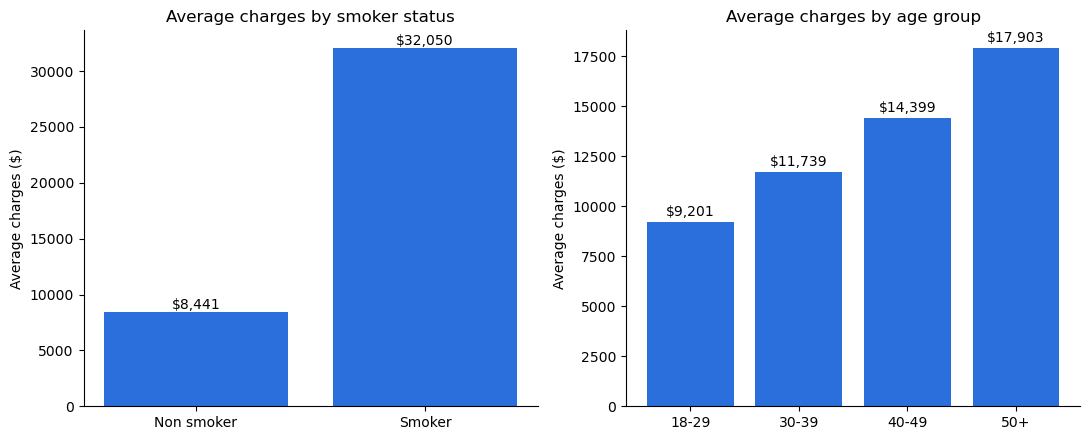

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

smoker_avg = insurance.groupby("smoker")["charges"].mean()
axes[0].bar(["Non smoker", "Smoker"], smoker_avg.values, color="#2A6FDB")
axes[0].set_title("Average charges by smoker status")

age_avg = insurance.groupby("age_group", observed=True)["charges"].mean()
axes[1].bar(age_avg.index.astype(str), age_avg.values, color="#2A6FDB")
axes[1].set_title("Average charges by age group")

for ax in axes:
    ax.set_ylabel("Average charges ($)")
    ax.spines[["top", "right"]].set_visible(False)
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 300,
                f"${p.get_height():,.0f}", ha="center")

plt.tight_layout()
plt.savefig("charges_by_smoker_and_age.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
#Retail: loyalty members vs non members
print(sales.groupby("loyalty_member")["total_price"]
      .agg(["count", "mean", "median", "sum"]).round(0))

                count    mean  median         sum
loyalty_member                                   
No              15657  3192.0  2534.0  49976751.0
Yes              4343  3137.0  2528.0  13625917.0


In [12]:
#Retail: cancellations
sales["cancelled"] = (sales["order_status"] == "Cancelled").astype(int)

for col in ["loyalty_member", "product_type", "payment_method", "shipping_type"]:
    print(sales.groupby(col)["cancelled"].agg(["count", "mean"]).round(3))
    print()

                count   mean
loyalty_member              
No              15657  0.329
Yes              4343  0.328

              count   mean
product_type              
Headphones     2011  0.323
Laptop         3973  0.324
Smartphone     5978  0.330
Smartwatch     3934  0.330
Tablet         4104  0.331

                count   mean
payment_method              
Bank Transfer    3371  0.330
Cash             2492  0.307
Credit Card      5868  0.336
Debit Card       2471  0.318
Paypal           5798  0.334

               count   mean
shipping_type              
Expedited       3272  0.325
Express         3366  0.338
Overnight       3357  0.331
Same Day        3280  0.333
Standard        6725  0.322



In [13]:
#Retail: product performance
completed = sales[sales["order_status"] == "Completed"]

print(completed.groupby("product_type").agg(
    purchases=("total_price", "count"),
    revenue=("total_price", "sum"),
    avg_price=("total_price", "mean")
).round(0).sort_values("revenue", ascending=False))

print()
print(sales.groupby("product_type")["rating"].mean().round(2))

              purchases     revenue  avg_price
product_type                                  
Smartphone         4004  14407836.0     3598.0
Smartwatch         2636   9398591.0     3565.0
Laptop             2686   8365905.0     3115.0
Tablet             2745   7722632.0     2813.0
Headphones         1361   2734651.0     2009.0

product_type
Headphones    2.99
Laptop        2.98
Smartphone    3.32
Smartwatch    2.99
Tablet        3.02
Name: rating, dtype: float64


In [14]:
#Retail: can we predict loyalty membership?
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

sales["loyalty_flag"] = sales["loyalty_member"].map({"Yes": 1, "No": 0})
features = ["age", "total_price", "unit_price", "quantity", "add_on_total", "rating"]
X, y = sales[features], sales["loyalty_flag"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=sales["customer_id"]))

model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=500))
model.fit(X.iloc[train_idx], y.iloc[train_idx])

y_test = y.iloc[test_idx]
pred = model.predict(X.iloc[test_idx])
prob = model.predict_proba(X.iloc[test_idx])[:, 1]

print("Baseline (guess No for everyone):", round(1 - y_test.mean(), 3))
print("Model accuracy:", round(accuracy_score(y_test, pred), 3))
print("F1:", round(f1_score(y_test, pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, prob), 3))

Baseline (guess No for everyone): 0.778
Model accuracy: 0.494
F1: 0.29
ROC AUC: 0.477


In [15]:
#Insurance: cross validation
from sklearn.model_selection import cross_val_score, KFold

X_ins = pd.get_dummies(insurance[["age", "bmi", "children", "smoker_flag", "region"]],
                       columns=["region"], drop_first=True)
y_ins = insurance["charges"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(LinearRegression(), X_ins, y_ins, cv=cv, scoring="r2")

print("R2 for each of the 5 splits:", scores.round(3))
print("Average R2:", round(scores.mean(), 3))

R2 for each of the 5 splits: [0.807 0.714 0.752 0.674 0.749]
Average R2: 0.739


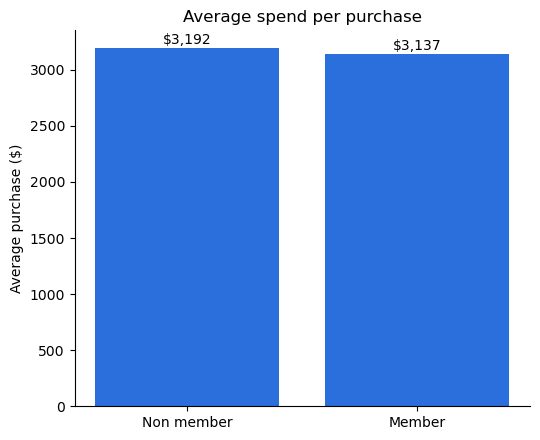

In [19]:
spend = sales.groupby("loyalty_member")["total_price"].mean()

plt.figure(figsize=(5.5, 4.5))
plt.bar(["Non member", "Member"], [spend["No"], spend["Yes"]], color="#2A6FDB")
plt.title("Average spend per purchase")
plt.ylabel("Average purchase ($)")
for i, v in enumerate([spend["No"], spend["Yes"]]):
    plt.text(i, v + 40, f"${v:,.0f}", ha="center")
plt.gca().spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("spend_by_loyalty.png", dpi=150, bbox_inches="tight")
plt.show()

## Question
Would a points program like the ones in retail work in health insurance?

## What the insurance data shows
- Smokers are charged about 3.8 times more on average ($32,050 against $8,441).
- Charges rise with age: the 50+ group averages $17,903, about 2 times the 18 to 29 group ($9,201).
- Obese customers average $15,572 against $10,409 for normal BMI. Region matters little.
- A linear regression explains about 74% of the differences in charges (5 fold cross validation, average R2 0.739).

## What the retail data shows
- Loyalty members do not spend more: $3,137 per purchase against $3,192 for non members.
- Cancellation rates are the same (32.8% and 32.9%) and flat across products, payment methods and shipping types.
- Purchase data cannot predict who is a member (ROC AUC 0.477, no better than chance).

## Recommendation
A rewards program should target smokers and customers aged 50 and over, who drive the highest charges. The retail data gives no evidence that points change behavior, so run a small pilot first and measure the result.

## Limits
- These are associations in two datasets, not proof of cause.
- The datasets describe different people and cannot be joined.
- In the retail file, 2,270 of 12,136 customers appear as both members and non members. The dataset notes that membership changes over time, so members and non members were compared per purchase, not per customer
- No program data was available, so the effect of points could not be measured.